# ToysAD-8K 2,000-Scene Selection Audit

This notebook validates the fixed 2,000-scene experiment corpus selected after the full-dataset EDA. It reports role sizes, object and anomaly strata, category coverage, anomaly-prefix coverage, the nested 100 plus 300 development pilot, and the indexed media inventory.

Official test scenes are excluded. Calibration and internal-lock labels remain separate from model-facing data. Source identifiers are used only to resolve the representative images and are not displayed or sent to ClearML.

## Runtime configuration

Local execution reads the ignored `.local` inputs. Kaggle execution reads the attached code snapshot, selection resources, development audit resources, and private ToysAD source. Paths can be overridden with the `VPI_*` environment variables used in the setup cell.

ClearML tracking is disabled by default for local runs and enabled for Kaggle runs. Kaggle reads `CLEARML_API_ACCESS_KEY` and `CLEARML_API_SECRET_KEY` from private Secrets. Secret values are not printed or written to the output folder.

In [1]:
from collections import Counter
from hashlib import sha256
from io import BytesIO
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys
import zipfile

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import PIL
from PIL import Image
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 120)

In [2]:
def find_code_root(start: Path) -> Path:
    """Find a local or attached code snapshot without printing private paths."""
    candidates = []
    configured = os.getenv("VPI_CODE_ROOT")
    if configured:
        candidates.append(Path(configured).expanduser())
    candidates.extend((start, *start.parents))
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        for mounted in sorted(kaggle_input.iterdir()):
            candidates.extend((mounted, mounted / "code"))
    for candidate in candidates:
        if (candidate / "src" / "visual_peer_inspector").is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not locate the code snapshot. Set VPI_CODE_ROOT to the directory containing src/visual_peer_inspector."
    )


def choose_directory(variable: str, default: Path, candidates: list[Path], marker: str) -> Path:
    """Resolve one required directory from configuration or known mount layouts."""
    configured = os.getenv(variable)
    ordered = [Path(configured).expanduser()] if configured else []
    ordered.extend([default, *candidates])
    for candidate in ordered:
        if candidate.is_dir() and (candidate / marker).exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not locate the required input for {variable}. Set it to a directory containing {marker}."
    )


def choose_file(variable: str, candidates: list[Path]) -> Path:
    configured = os.getenv(variable)
    ordered = [Path(configured).expanduser()] if configured else []
    ordered.extend(candidates)
    for candidate in ordered:
        if candidate.is_file():
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate {variable}. Set it to the required file.")


def read_json_lines(path: Path) -> list[dict]:
    """Read trusted JSON Lines without displaying restricted fields."""
    rows = []
    with path.open("r", encoding="utf-8") as handle:
        for line in handle:
            if line.strip():
                rows.append(json.loads(line))
    return rows


def file_sha256(path: Path) -> str:
    digest = sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def prepare_clearml_tracking(execution_environment: str) -> str:
    """Prepare optional tracking without exposing credential values."""
    default_mode = "online" if execution_environment == "kaggle" else "disabled"
    tracking_mode = os.getenv("VPI_TRACKING_MODE", default_mode).lower()
    os.environ["VPI_TRACKING_MODE"] = tracking_mode
    os.environ.setdefault("CLEARML_LOG_ENVIRONMENT", "")

    if tracking_mode == "disabled":
        return tracking_mode

    if importlib.util.find_spec("clearml") is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", "clearml==2.1.10"]
        )

    if tracking_mode == "online" and execution_environment == "kaggle":
        from kaggle_secrets import UserSecretsClient

        secret_client = UserSecretsClient()
        for secret_name in ("CLEARML_API_ACCESS_KEY", "CLEARML_API_SECRET_KEY"):
            try:
                secret_value = secret_client.get_secret(secret_name)
            except Exception as error:
                raise RuntimeError(
                    f"Kaggle Secret {secret_name} is missing or is not enabled for this notebook."
                ) from error
            if not secret_value:
                raise RuntimeError(f"Kaggle Secret {secret_name} is empty.")
            os.environ[secret_name] = secret_value

        os.environ.setdefault("CLEARML_API_HOST", "https://api.clear.ml")
        os.environ.setdefault("CLEARML_WEB_HOST", "https://app.clear.ml")
        os.environ.setdefault("CLEARML_FILES_HOST", "https://files.clear.ml")

    return tracking_mode

In [3]:
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/working").is_dir() else "local"
if EXECUTION_ENVIRONMENT == "kaggle":
    os.environ.setdefault("VPI_GIT_COMMIT", "7abcb49197f23d576433e5b76426f1046e977517")
    os.environ.setdefault("VPI_GIT_DIRTY", "true")
    os.environ.setdefault(
        "VPI_KAGGLE_DATASET_VERSION",
        "esreekarreddy/vpi-toysad-selection-audit-inputs/1; "
        "esreekarreddy/toysad8k-full-private-eda/1",
    )
    os.environ.setdefault("VPI_KAGGLE_NOTEBOOK_VERSION", "4")
TRACKING_MODE = prepare_clearml_tracking(EXECUTION_ENVIRONMENT)
CODE_ROOT = find_code_root(Path.cwd().resolve())
sys.path.insert(0, str(CODE_ROOT / "src"))

from visual_peer_inspector.data.toysad_selection import (
    audit_routine_release,
    verify_repeat_build_evidence,
)
from visual_peer_inspector.tracking import ExperimentTracker

kaggle_input = Path("/kaggle/input")
mounted_roots = sorted(kaggle_input.iterdir()) if kaggle_input.is_dir() else []
local_selection = CODE_ROOT / ".local" / "toysad" / "selection" / "toysad8k-train-2000-v2"
SELECTION_ROOT = choose_directory(
    "VPI_SELECTION_ROOT",
    local_selection,
    [root for mounted in mounted_roots for root in (mounted, mounted / "toysad8k-train-2000-v2")],
    "selection_audit.json",
)
DEVELOPMENT_ROOT = choose_directory(
    "VPI_DEVELOPMENT_ROOT",
    local_selection.with_name(local_selection.name + "-development"),
    [root for mounted in mounted_roots for root in (mounted, mounted / "toysad8k-train-2000-v2-development")],
    "development_source_map.jsonl",
)
SOURCE_ROOT = choose_directory(
    "VPI_SOURCE_ROOT",
    CODE_ROOT / ".local" / "toysad" / "kaggle" / "toysad8k-full-private-v1",
    [
        Path("/kaggle/input/datasets/esreekarreddy/toysad8k-full-private-eda"),
        Path("/kaggle/input/toysad8k-full-private-eda"),
        *mounted_roots,
    ],
    "toysad8k_scene_master.json",
)
REPEAT_BUILD_EVIDENCE = choose_file(
    "VPI_REPEAT_BUILD_EVIDENCE",
    [
        SELECTION_ROOT.parent / "toysad8k-train-2000-v2.repeat-build-verification.json",
        SELECTION_ROOT / "toysad8k-train-2000-v2.repeat-build-verification.json",
    ],
)
default_report_root = (
    Path("/kaggle/working/toysad8k_selection_audit")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else CODE_ROOT / "reports" / "selection" / "toysad8k_train_2000_v2"
)
REPORT_ROOT = Path(os.getenv("VPI_REPORT_ROOT", str(default_report_root))).expanduser().resolve()
REPORT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Execution environment: {EXECUTION_ENVIRONMENT}")
print("Required trusted inputs found: code, selection, development audit, source, repeat-build evidence")
print(f"Output folder name: {REPORT_ROOT.name}")
print(f"Requested tracking mode: {TRACKING_MODE}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.5 MB/s eta 0:00:00
Execution environment: kaggle
Required trusted inputs found: code, selection, development audit, source, repeat-build evidence
Output folder name: toysad8k_selection_audit
Requested tracking mode: online


In [4]:
routine_check = audit_routine_release(SELECTION_ROOT, DEVELOPMENT_ROOT)
audit = routine_check["selection_audit"]
repeat_build_verification = verify_repeat_build_evidence(
    REPEAT_BUILD_EVIDENCE,
    {"routine_release": SELECTION_ROOT, "development_workspace": DEVELOPMENT_ROOT},
)
development_rows = read_json_lines(DEVELOPMENT_ROOT / "development_source_map.jsonl")

tracking_properties = {
    "execution_environment": EXECUTION_ENVIRONMENT,
    "release_id": audit["release_id"],
    "notebook_name": "02_toysad8k_2000_selection_audit.ipynb",
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "matplotlib_version": matplotlib.__version__,
    "pillow_version": PIL.__version__,
    "notebook_sha256": os.getenv("VPI_NOTEBOOK_SHA256", "not-recorded"),
    "git_commit": os.getenv("VPI_GIT_COMMIT", "not-recorded"),
    "git_dirty": os.getenv("VPI_GIT_DIRTY", "not-recorded"),
    "kaggle_dataset_version": os.getenv("VPI_KAGGLE_DATASET_VERSION", "not-applicable"),
    "kaggle_notebook_version": os.getenv("VPI_KAGGLE_NOTEBOOK_VERSION", "not-applicable"),
    "selection_checksum_file_sha256": file_sha256(SELECTION_ROOT / "checksums.sha256"),
    "development_checksum_file_sha256": file_sha256(DEVELOPMENT_ROOT / "checksums.sha256"),
    "repeat_build_evidence_sha256": file_sha256(REPEAT_BUILD_EVIDENCE),
    "source_master_sha256": file_sha256(SOURCE_ROOT / "toysad8k_scene_master.json"),
}
tracking_configuration = {
    "protocol_id": "toysad8k-train-2000-v2",
    "selected_scene_target": 2000,
    "views_per_scene": 20,
    "development_target": 1000,
    "calibration_target": 600,
    "internal_lock_target": 400,
}
tracking_properties["configuration_sha256"] = sha256(
    json.dumps(tracking_configuration, sort_keys=True, separators=(",", ":")).encode("utf-8")
).hexdigest()
tracker = ExperimentTracker.start(
    project_name="Visual Peer Inspector/01 Data Preparation",
    task_name=(
        f"selection-audit-{EXECUTION_ENVIRONMENT}-"
        f"v{os.getenv('VPI_KAGGLE_NOTEBOOK_VERSION', 'local')}"
    ),
    task_type="data_processing",
    properties=tracking_properties,
    configuration=tracking_configuration,
)

print(f"Selection release: {audit['release_id']}")
print(f"Audit passed: {audit['passed']}")
print(f"Development rows loaded: {len(development_rows):,}")
print(f"Model-facing field allowlist verified: {routine_check['model_facing_fields_verified']}")
print(f"Byte-identical repeat build: {repeat_build_verification['byte_identical']}")
print(f"Tracking mode: {tracker.mode}")

ClearML Task: created new task id=ce9b220344b2435fac60d8e180c37fdd


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


ClearML results page: https://app.clear.ml/projects/3b152e3d0ea24f3cbfd58ae36ff965fd/experiments/ce9b220344b2435fac60d8e180c37fdd/output/log
2026-08-22 23:23:42,611 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
Selection release: toysad8k-train-2000-v2
Audit passed: True
Development rows loaded: 1,000
Model-facing field allowlist verified: True
Byte-identical repeat build: True
Tracking mode: online


## 1. Selection summary

The eligible pool contains available training scenes whose base asset does not occur in the official seen-test split. The selected corpus deliberately increases coverage of four-object, five-object, and two-anomaly cases. It is not intended to reproduce the natural frequency of every ToysAD stratum.

In [5]:
eligible_summary = audit["design"]["eligible_pool"]
selected_summary = audit["design"]["selected_corpus"]
summary_table = pd.DataFrame(
    [
        {"Measure": "Eligible scenes", "Value": eligible_summary["scene_count"]},
        {"Measure": "Eligible base assets", "Value": eligible_summary["asset_count"]},
        {"Measure": "Eligible categories", "Value": eligible_summary["category_count"]},
        {"Measure": "Selected scenes", "Value": selected_summary["scene_count"]},
        {"Measure": "Selected base assets", "Value": selected_summary["asset_count"]},
        {"Measure": "Views per selected scene", "Value": 20},
        {"Measure": "Selected RGB images", "Value": audit["selected_media"]["component_counts"]["rgb"]},
        {"Measure": "Official test scenes selected", "Value": selected_summary["official_test_scene_count"]},
        {"Measure": "Assets crossing roles", "Value": selected_summary["asset_role_overlap_count"]},
    ]
)
summary_display = summary_table.copy()
summary_display["Value"] = summary_display["Value"].map(lambda value: f"{value:,}")
display(summary_display)
summary_table.to_csv(REPORT_ROOT / "selection_summary.csv", index=False)

,Measure,Value
0,Eligible scenes,"4,107"
1,Eligible base assets,545
2,Eligible categories,39
3,Selected scenes,"2,000"
4,Selected base assets,545
5,Views per selected scene,20
6,Selected RGB images,"40,000"
7,Official test scenes selected,0
8,Assets crossing roles,0


## 2. Development, calibration, and internal lock

A base asset stays inside one role. Development is used to build and compare the method. Calibration is used only after the method is frozen. Internal lock is opened once after predictions and settings are saved and hashed.

,Role,Scenes,Base assets,Three-scene assets,Four-scene assets,Categories
0,Development,1000,273,92,181,39
1,Calibration,600,163,52,111,38
2,Internal lock,400,109,36,73,39


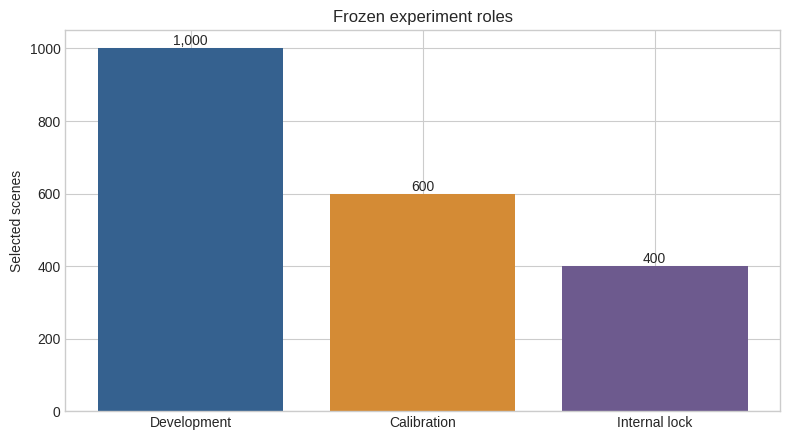

In [6]:
role_order = ["development", "calibration", "internal_lock"]
role_labels = ["Development", "Calibration", "Internal lock"]
role_reports = selected_summary["role_reports"]
role_table = pd.DataFrame(
    [
        {
            "Role": label,
            "Scenes": role_reports[role]["scene_count"],
            "Base assets": role_reports[role]["asset_count"],
            "Three-scene assets": role_reports[role]["asset_multiplicity"]["3"],
            "Four-scene assets": role_reports[role]["asset_multiplicity"]["4"],
            "Categories": role_reports[role]["category_count"],
        }
        for role, label in zip(role_order, role_labels)
    ]
)
display(role_table)
role_table.to_csv(REPORT_ROOT / "role_counts.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(role_table["Role"], role_table["Scenes"], color=["#35618f", "#d48b35", "#6d5a8e"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_ylabel("Selected scenes")
ax.set_title("Frozen experiment roles")
fig.tight_layout()
fig.savefig(REPORT_ROOT / "role_scene_counts.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Object and anomaly strata

Each role contains all five native ToysAD strata used by the project. Results are reported by stratum and as an overall aggregate.

,Objects x anomalies,Development,Calibration,Internal lock,Total
0,3x1,307,296,197,800
1,4x1,185,129,86,400
2,4x2,206,56,38,300
3,5x1,158,85,57,300
4,5x2,144,34,22,200


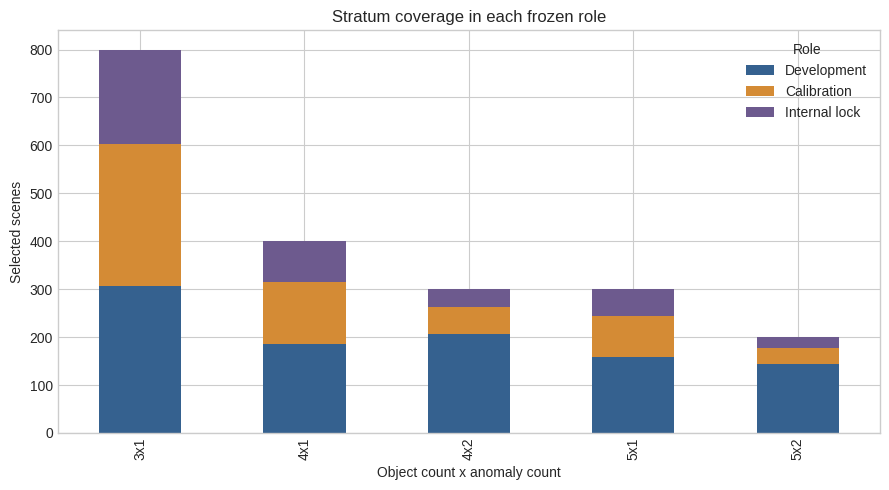

In [7]:
stratum_order = ["3x1", "4x1", "4x2", "5x1", "5x2"]
stratum_rows = []
for stratum in stratum_order:
    row = {"Objects x anomalies": stratum}
    for role, label in zip(role_order, role_labels):
        row[label] = role_reports[role]["strata"][stratum]
    row["Total"] = sum(row[label] for label in role_labels)
    stratum_rows.append(row)
stratum_table = pd.DataFrame(stratum_rows)
display(stratum_table)
stratum_table.to_csv(REPORT_ROOT / "strata_by_role.csv", index=False)

plot_data = stratum_table.set_index("Objects x anomalies")[role_labels]
ax = plot_data.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#35618f", "#d48b35", "#6d5a8e"])
ax.set_xlabel("Object count x anomaly count")
ax.set_ylabel("Selected scenes")
ax.set_title("Stratum coverage in each frozen role")
ax.legend(title="Role")
plt.tight_layout()
plt.savefig(REPORT_ROOT / "strata_by_role.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Nested development pilot

The 400-scene technical pilot is part of development. The 100-scene screen supports installation, runtime, and bounded component comparisons. The separate 300 scenes confirm frozen screen choices. Neither part is the internal lock.

In [8]:
pilot_order = ["screen_100", "confirm_300", "remainder_600"]
pilot_labels = ["Screen 100", "Confirm 300", "Remaining development 600"]
pilot_reports = selected_summary["pilot_reports"]
pilot_table = pd.DataFrame(
    [
        {
            "Stage": label,
            "Scenes": pilot_reports[stage]["scene_count"],
            "Base assets": pilot_reports[stage]["asset_count"],
            "Categories": pilot_reports[stage]["category_count"],
            "Anomaly prefixes": len(pilot_reports[stage]["prefix_scene_presence_counts"]),
        }
        for stage, label in zip(pilot_order, pilot_labels)
    ]
)
display(pilot_table)
pilot_table.to_csv(REPORT_ROOT / "development_pilot_counts.csv", index=False)

pilot_union_categories = {
    row["category"]
    for row in development_rows
    if row["pilot_stage"] in {"screen_100", "confirm_300"}
}
print(f"Categories covered by the full 400-scene pilot: {len(pilot_union_categories)} of 39")
print("Nested development pilot verified")

,Stage,Scenes,Base assets,Categories,Anomaly prefixes
0,Screen 100,100,27,27,8
1,Confirm 300,300,82,39,8
2,Remaining development 600,600,164,32,8


Categories covered by the full 400-scene pilot: 39 of 39
Nested development pilot verified


## 5. Category and anomaly-prefix coverage

Development and internal lock cover all 39 eligible categories. Calibration covers 38 because one rare category has only enough eligible base assets for development and internal lock. All eight raw anomaly prefixes occur in every role. Rare-prefix results still require cautious interpretation.

In [9]:
development_prefixes = role_reports["development"]["prefix_scene_presence_counts"]
development_objects = role_reports["development"]["prefix_anomalous_object_counts"]
prefix_table = pd.DataFrame(
    [
        {
            "Prefix": prefix,
            "Development scenes": development_prefixes[prefix],
            "Development anomalous objects": development_objects[prefix],
        }
        for prefix in sorted(development_prefixes)
    ]
)
display(prefix_table)
prefix_table.to_csv(REPORT_ROOT / "development_anomaly_prefix_counts.csv", index=False)

category_coverage = pd.DataFrame(
    {
        "Role": role_labels,
        "Covered categories": [role_reports[role]["category_count"] for role in role_order],
        "Eligible categories": [39, 39, 39],
        "Anomaly prefix coverage": [role_reports[role]["anomaly_prefix_coverage_count"] for role in role_order],
    }
)
display(category_coverage)
category_coverage.to_csv(REPORT_ROOT / "category_coverage.csv", index=False)

,Prefix,Development scenes,Development anomalous objects
0,bump,75,83
1,crack,263,283
2,defr,44,44
3,disc,335,394
4,frac,263,287
5,miss,188,205
6,rota,28,31
7,tran,23,23


,Role,Covered categories,Eligible categories,Anomaly prefix coverage
0,Development,39,39,8
1,Calibration,38,39,8
2,Internal lock,39,39,8


## 6. Indexed selected-media inventory

The source remains zipped locally and may be unpacked inside the private Kaggle mount. The selector verified 238,000 required paths in the pinned archive index and CRC-read the scene3d metadata used to resolve object names. This section reports the indexed inventory; it does not claim current-byte media validation.

In [10]:
component_names = {
    "rgb": "RGB images",
    "scene_mask": "Whole-scene masks",
    "object_mask": "Object masks",
    "scene2d_metadata": "Source scene2d metadata",
    "scene3d_metadata": "Source scene3d metadata",
}
media_counts = audit["selected_media"]["component_counts"]
media_bytes = audit["selected_media"]["component_uncompressed_bytes"]
media_table = pd.DataFrame(
    [
        {
            "Component": component_names[component],
            "Indexed files": media_counts[component],
            "Indexed uncompressed GiB": media_bytes[component] / (1024 ** 3),
            "Planned model-safe media": component in {"rgb", "scene_mask", "object_mask"},
        }
        for component in component_names
    ]
)
media_display = media_table.copy()
media_display["Indexed files"] = media_display["Indexed files"].map(lambda value: f"{value:,}")
media_display["Indexed uncompressed GiB"] = media_display["Indexed uncompressed GiB"].map(lambda value: f"{value:.3f}")
display(media_display)
media_table.to_csv(REPORT_ROOT / "selected_media_inventory.csv", index=False)
print(f"Total required source paths indexed: {audit['selected_media']['member_count']:,}")
print(f"Media files planned for opaque packaging: {sum(media_counts[key] for key in ('rgb', 'scene_mask', 'object_mask')):,}")

,Component,Indexed files,Indexed uncompressed GiB,Planned model-safe media
0,RGB images,"40,000",4.736,True
1,Whole-scene masks,"40,000",0.050,True
2,Object masks,"154,000",4.911,True
3,Source scene2d metadata,"2,000",0.004,False
4,Source scene3d metadata,"2,000",0.046,False


Total required source paths indexed: 238,000
Media files planned for opaque packaging: 234,000


## 7. Representative selected RGB views

One screen-stage scene is shown from each object and anomaly stratum. Titles use only opaque scene IDs. The helper reads either the local source ZIP or the equivalent unpacked Kaggle layout, so both environments use the same analysis source.

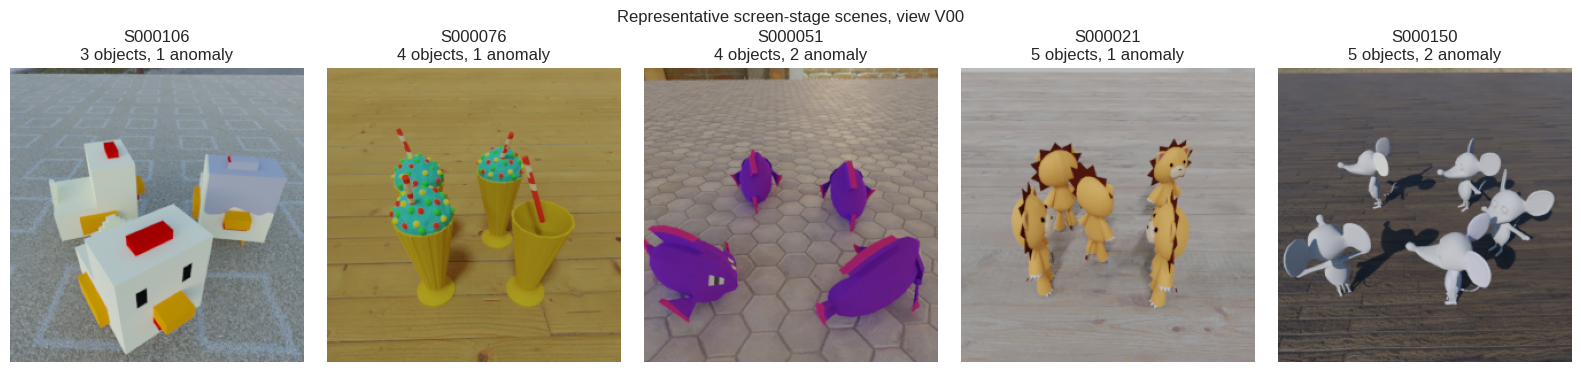

In [11]:
def read_source_rgb(source_root: Path, source_scene_id: str, view_id: str) -> Image.Image:
    """Read one RGB view from the verified ZIP or unpacked Kaggle source."""
    source_member = f"toysad8k/{source_scene_id}/RGB/{view_id}.png"
    zip_path = source_root / "toysAD8K.zip"
    if zip_path.is_file():
        with zipfile.ZipFile(zip_path) as archive:
            with Image.open(BytesIO(archive.read(source_member))) as image:
                return image.convert("RGB")

    unpacked_candidates = [
        source_root / "toysAD8K" / source_member,
        source_root / source_member,
        source_root / source_scene_id / "RGB" / f"{view_id}.png",
    ]
    for candidate in unpacked_candidates:
        if candidate.is_file():
            with Image.open(candidate) as image:
                return image.convert("RGB")
    raise FileNotFoundError("The requested RGB view was not found in the configured source root.")


screen_rows = sorted(
    (row for row in development_rows if row["pilot_stage"] == "screen_100"),
    key=lambda row: row["opaque_scene_id"],
)
representatives = []
for stratum in [(3, 1), (4, 1), (4, 2), (5, 1), (5, 2)]:
    representatives.append(
        next(row for row in screen_rows if (row["object_count"], row["anomaly_count"]) == stratum)
    )

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for axis, row in zip(axes, representatives):
    image = read_source_rgb(SOURCE_ROOT, row["source_scene_id"], "0000")
    axis.imshow(image)
    axis.set_title(f"{row['opaque_scene_id']}\n{row['object_count']} objects, {row['anomaly_count']} anomaly")
    axis.axis("off")
fig.suptitle("Representative screen-stage scenes, view V00", y=1.02)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "representative_selected_views.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Audit result

The selection audit passes when every required gate below is marked `PASS`.

In [12]:
gate_table = pd.DataFrame(
    [
        {"Gate": "Pinned compact selection inputs", "Status": "PASS"},
        {"Gate": "4,107-scene eligibility audit", "Status": "PASS"},
        {"Gate": "Exact 2,000 scenes and 545 asset groups", "Status": "PASS"},
        {"Gate": "No asset crosses experiment roles", "Status": "PASS"},
        {"Gate": "Exact 100 plus 300 nested pilot", "Status": "PASS"},
        {"Gate": "238,000 required source paths indexed", "Status": "PASS"},
        {"Gate": "Byte-identical repeat build", "Status": "PASS" if repeat_build_verification["byte_identical"] else "FAIL"},
        {"Gate": "Full private source available in this environment", "Status": "PASS"},
    ]
)
display(gate_table)
gate_table.to_csv(REPORT_ROOT / "selection_gate_status.csv", index=False)

aggregate_report = {
    "release_id": audit["release_id"],
    "audit_passed": audit["passed"],
    "eligible_scene_count": eligible_summary["scene_count"],
    "selected_scene_count": selected_summary["scene_count"],
    "selected_asset_count": selected_summary["asset_count"],
    "required_indexed_path_count": audit["selected_media"]["member_count"],
    "official_test_scene_count": selected_summary["official_test_scene_count"],
    "asset_role_overlap_count": selected_summary["asset_role_overlap_count"],
    "byte_identical_repeat_build": repeat_build_verification["byte_identical"],
}
with (REPORT_ROOT / "selection_aggregate.json").open("w", encoding="utf-8") as handle:
    json.dump(aggregate_report, handle, indent=2, sort_keys=True)
    handle.write("\n")

run_record = {
    **tracking_properties,
    "tracking_mode": tracker.mode,
    "clearml_task_id": tracker.task_id or "not-created",
    "audit_passed": audit["passed"],
    "repeat_build_passed": repeat_build_verification["byte_identical"],
}
with (REPORT_ROOT / "run_record.json").open("w", encoding="utf-8") as handle:
    json.dump(run_record, handle, indent=2, sort_keys=True)
    handle.write("\n")

tracker.report_scalar(title="Selection audit", series="eligible scenes", value=eligible_summary["scene_count"])
tracker.report_scalar(title="Selection audit", series="selected scenes", value=selected_summary["scene_count"])
tracker.report_scalar(title="Selection audit", series="selected assets", value=selected_summary["asset_count"])
tracker.report_scalar(title="Selection audit", series="required indexed paths", value=audit["selected_media"]["member_count"])
tracker.upload_summary("selection aggregate", aggregate_report)

artifact_rows = []
for path in sorted(REPORT_ROOT.iterdir()):
    if path.is_file() and path.name != "artifact_manifest.csv":
        artifact_rows.append({"File": path.name, "Bytes": path.stat().st_size, "SHA256": file_sha256(path)})
artifact_manifest = pd.DataFrame(artifact_rows)
artifact_manifest.to_csv(REPORT_ROOT / "artifact_manifest.csv", index=False)
tracker.close()

display(artifact_manifest)
print(f"Aggregate audit files written to: {REPORT_ROOT.name}")

,Gate,Status
0,Pinned compact selection inputs,PASS
1,"4,107-scene eligibility audit",PASS
2,"Exact 2,000 scenes and 545 asset groups",PASS
3,No asset crosses experiment roles,PASS
4,Exact 100 plus 300 nested pilot,PASS
5,"238,000 required source paths indexed",PASS
6,Byte-identical repeat build,PASS
7,Full private source available in this environment,PASS


,File,Bytes,SHA256
0,category_coverage.csv,130,e9186ca40a8ddd36774d049150876999dce5f78dc48a8ca251fde13e49916cdc
1,development_anomaly_prefix_counts.csv,153,d72e2ea70797e793c52b1f2dfda9706574fe304b50d9630237633a950bd079fd
2,development_pilot_counts.csv,139,f1d01a6eb80b6674c88d0d9482ed5e5f825dd55e72d190e0824e16fec0447821
3,representative_selected_views.png,1464983,c556824f21a587b3add38aecce41f3e3acae7c3089fa64d85060ec5aec0cd050
4,role_counts.csv,164,e1b9c1698e39b23bd56bb2c0f176ae44117f202558e13ec2e4664a35b15d2a81
5,role_scene_counts.png,36450,b06e6e0f8a8031c4e0cabc7a3af52a65bfee3b7afdb3cb331eb04e482a11b10a
6,run_record.json,1186,dada2646a5296f25e6a17dfbb912e3b55f523510db06ffe8a80a7b9af0c5489d
7,selected_media_inventory.csv,317,acec28cdd367c65d044d2384121db71e9bb04dc475332afe12fe7a8afe8d77f6
8,selection_aggregate.json,311,f5631b700040754a6a349faee0f669ad5185c973fbb59d63eb3227b6430affea
9,selection_gate_status.csv,342,0c4387e23c2a95fc484812194b556ec3b40a853e3ce626c69fb0afea7843b4ea


Aggregate audit files written to: toysad8k_selection_audit
